# 03. 군집 — 지역/단지 유사군 탐색

`02_eda_feature_engineering.ipynb`에서 저장한 `data/processed/df_fe.parquet`를 불러와 KMeans로 군집화합니다.

다섯 버전을 비교합니다.
- **버전 A — 지역 포함**: 지역이 군집을 얼마나 지배하는지 확인
- **버전 B — 지역 제외**: 지역과 무관하게 존재하는 매물 유형(숨겨진 패턴)을 찾기 위함
- **버전 C — 생활 인프라 접근성**: 역세권·초/중/고 거리만으로 군집화 — "교통 중심 vs 학군 중심" 같은 인프라 유형 발견, 타겟 고객군별(1인가구/자녀가구) 매물 추천에 활용
- **버전 D — 가격·평형 소비자 세그먼트**: 가격·평형·평당가로 군집화 — "신혼부부용 소형", "자산가용 대형" 같은 명확한 소비자 타겟군 도출
- **버전 E — 가격 대비 인프라(투자 매력도)**: 평당가·연식·거리 조합으로 군집화 — "가격은 낮은데 인프라는 좋은" 잠재 저평가 지역군 탐색, 05(분류)의 저평가 스크리닝과 연결

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"

df_fe = pd.read_parquet(PROCESSED_DIR / "df_fe.parquet")
price_col = "거래금액"
print(df_fe.shape)


(81541, 83)


In [3]:
# 평당가도 log_price와 동일한 이유로 로그변환 (오른쪽 꼬리가 긴 분포 -> 군집화 왜곡 방지)
df_fe["log_평당가"] = np.log1p(df_fe["평당가"])


## 0. 지역평균가 계산

`02`에서는 `지역평균가`를 만들지 않았습니다 (회귀에서 train/test 누수를 막기 위해 회귀 노트북으로 옮김). 군집화는 train/test 분리가 없는 비지도학습이라 누수 개념이 적용되지 않으므로, 여기서는 **전체 데이터 기준**으로 자유롭게 계산합니다.

In [4]:
df_fe["법정동시군구코드"] = df_fe["법정동시군구코드"].astype(str)
df_fe["지역평균가"] = df_fe.groupby("법정동시군구코드")[price_col].transform("mean")


## 버전 A — 지역 포함

**피처**: `전용면적`, `층`, `연식`, `지역평균가`, `log_price`, `법정동시군구코드`(원-핫)

> 탐색 단계에서는 `sample_size=5000`으로 실루엣 스코어를 근사 계산해 속도를 확보하고, 최종 선택된 k에 대해서만 전체 데이터로 한 번 더 정확히 검증합니다 (전체 데이터 실루엣 계산은 O(n²)이라 8만 건 규모에서는 k 하나당도 시간이 걸릴 수 있습니다).

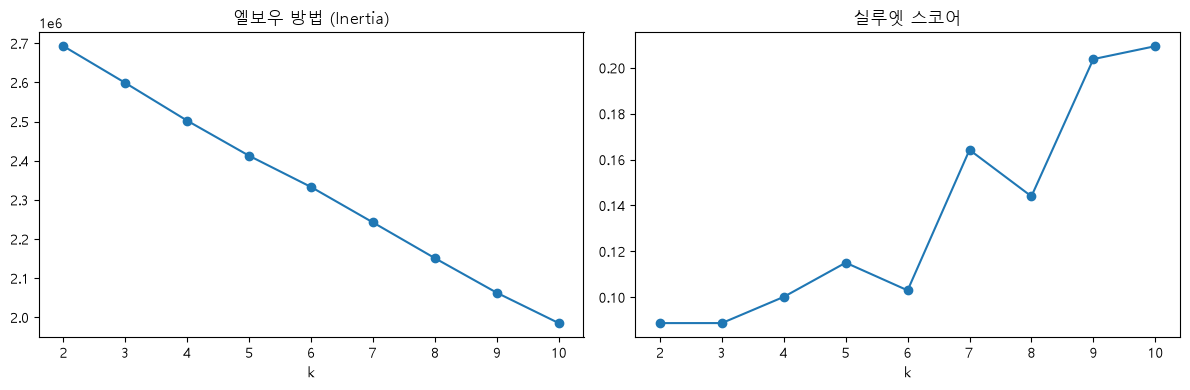

k=2: silhouette=0.0887
k=3: silhouette=0.0887
k=4: silhouette=0.1001
k=5: silhouette=0.1150
k=6: silhouette=0.1030
k=7: silhouette=0.1642
k=8: silhouette=0.1440
k=9: silhouette=0.2038
k=10: silhouette=0.2094


In [8]:
cluster_features_num = ["전용면적", "층", "연식", "지역평균가", "log_price"]
cluster_features_cat = ["법정동시군구코드"]

df_cluster = df_fe[cluster_features_num + cluster_features_cat].dropna().copy()
df_cluster_encoded = pd.get_dummies(df_cluster, columns=cluster_features_cat)

scaler = StandardScaler()
X_cluster = scaler.fit_transform(df_cluster_encoded)

inertia_list, silhouette_list = [], []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertia_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_cluster, labels, sample_size=5000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertia_list, marker="o")
axes[0].set_title("엘보우 방법 (Inertia)")
axes[0].set_xlabel("k")
axes[1].plot(list(k_range), silhouette_list, marker="o")
axes[1].set_title("실루엣 스코어")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouette_list):
    print(f"k={k}: silhouette={s:.4f}")


In [9]:
# 최종 군집화 (실루엣 스코어 최고점 k=10 기준. 지역 원-핫이 지배적이라 k가 커질수록
# 사실상 구 단위 분할에 근접함 — 이 버전 자체가 "지역이 얼마나 강한 신호인지" 보여주는 대조군이므로 통계적 최고점을 그대로 채택)
final_k = 10
kmeans_a = KMeans(n_clusters=final_k, random_state=42, n_init=10)
df_cluster_encoded["cluster"] = kmeans_a.fit_predict(X_cluster)

df_cluster_encoded["거래금액_복원"] = np.expm1(df_cluster_encoded["log_price"])
summary_cols = ["전용면적", "층", "연식", "지역평균가", "거래금액_복원"]
cluster_summary_a = df_cluster_encoded.groupby("cluster")[summary_cols].mean().round(1)
cluster_summary_a["건수"] = df_cluster_encoded["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_a = silhouette_score(X_cluster, kmeans_a.labels_)
print(f"최종 k={final_k} 전체 데이터 기준 실루엣 스코어: {final_sil_a:.4f}")

cluster_summary_a


최종 k=10 전체 데이터 기준 실루엣 스코어: 0.2132


,전용면적,층,연식,지역평균가,거래금액_복원,건수
cluster,,,,,,
0,77.8,10.1,19.3,93413.0,93413.0,4396
1,84.3,9.8,23.5,235046.7,235284.0,9603
2,75.5,9.2,23.3,127407.4,127280.9,18021
3,71.8,10.0,21.6,68697.7,68697.7,30363
4,75.2,10.2,19.2,133073.0,133073.0,4012
5,70.2,10.1,23.7,73679.4,73679.4,4086
6,77.1,9.8,20.7,168894.5,168894.5,2309
7,73.4,8.6,14.7,86736.0,86736.0,3385
8,68.0,8.5,30.9,57375.9,57375.9,2577


In [10]:
# 구별 분포 확인 — 클러스터가 지역과 얼마나 겹치는지
df_fe.loc[df_cluster_encoded.index, "cluster_region"] = df_cluster_encoded["cluster"].values
pd.crosstab(df_fe["시군구명"], df_fe["cluster_region"])


cluster_region,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0
시군구명,,,,,,,,,,
강남구,0,2855,0,0,0,0,0,0,0,0
강동구,0,0,0,0,4012,0,0,0,0,0
강북구,0,0,0,1510,0,0,0,0,0,0
강서구,0,0,4877,1483,0,0,0,0,0,0
관악구,0,0,0,2596,0,0,0,0,0,0
광진구,0,0,1392,0,0,0,0,0,0,0
구로구,0,0,0,0,0,4086,0,0,0,0
금천구,0,0,0,1231,0,0,0,0,0,0
노원구,0,0,0,7460,0,0,0,0,0,0


지역 원-핫이 포함되면 클러스터가 거의 구 단위로 1:1 대응합니다 (예: 종로구=클러스터0, 성동구=클러스터1 등). 즉 지역 정보가 다른 피처의 영향력을 사실상 압도합니다 — 이 자체는 "머신러닝이 지역을 재확인한 것"에 가까워 새로운 인사이트로 보기는 어렵습니다.

## 버전 B — 지역 제외 (순수 특성만)

**피처**: `전용면적`, `층`, `연식`, `log_price`

지역을 빼고 순수 매물 특성만으로 군집화하면, 지역을 초월해서 존재하는 매물 유형을 발견할 수 있는지 확인합니다.

> 탐색 단계에서는 `sample_size=5000`으로 실루엣 스코어를 근사 계산해 속도를 확보하고, 최종 선택된 k에 대해서만 전체 데이터로 한 번 더 정확히 검증합니다 (전체 데이터 실루엣 계산은 O(n²)이라 8만 건 규모에서는 k 하나당도 시간이 걸릴 수 있습니다).

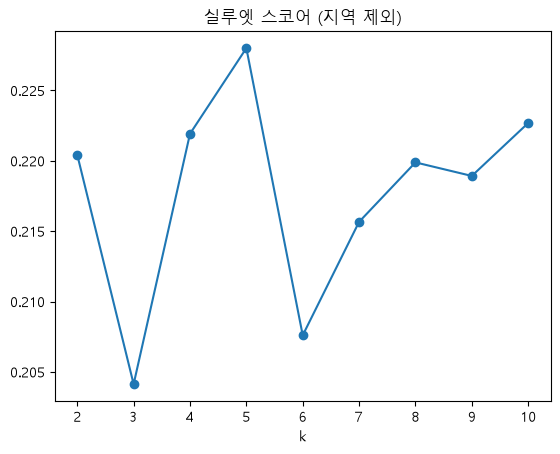

k=2: silhouette=0.2204
k=3: silhouette=0.2041
k=4: silhouette=0.2219
k=5: silhouette=0.2280
k=6: silhouette=0.2076
k=7: silhouette=0.2157
k=8: silhouette=0.2199
k=9: silhouette=0.2189
k=10: silhouette=0.2227


In [11]:
cluster_features_pure = ["전용면적", "층", "연식", "log_price"]
df_cluster_pure = df_fe[cluster_features_pure].dropna().copy()

scaler_pure = StandardScaler()
X_cluster_pure = scaler_pure.fit_transform(df_cluster_pure)

silhouette_list_pure = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_pure)
    silhouette_list_pure.append(silhouette_score(X_cluster_pure, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_pure, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (지역 제외)")
plt.show()

for k, s in zip(k_range, silhouette_list_pure):
    print(f"k={k}: silhouette={s:.4f}")


In [12]:
# 최종 군집화 (위 실루엣 스코어 그래프 보고 k 직접 지정)
final_k_pure = 5
kmeans_b = KMeans(n_clusters=final_k_pure, random_state=42, n_init=10)
df_cluster_pure["cluster"] = kmeans_b.fit_predict(X_cluster_pure)

df_cluster_pure["거래금액_복원"] = np.expm1(df_cluster_pure["log_price"])
summary_cols = ["전용면적", "층", "연식", "거래금액_복원"]
cluster_summary_b = df_cluster_pure.groupby("cluster")[summary_cols].mean().round(1)
cluster_summary_b["건수"] = df_cluster_pure["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_b = silhouette_score(X_cluster_pure, kmeans_b.labels_)
print(f"최종 k={final_k_pure} 전체 데이터 기준 실루엣 스코어: {final_sil_b:.4f}")

cluster_summary_b


최종 k=5 전체 데이터 기준 실루엣 스코어: 0.2307


,전용면적,층,연식,거래금액_복원,건수
cluster,,,,,
0,79.6,19.5,16.1,134947.1,14843
1,62.9,7.4,31.9,76200.2,28185
2,120.2,8.5,28.0,208444.7,9963
3,38.8,9.7,10.9,28177.2,6276
4,76.8,6.5,14.0,120943.9,22274


In [13]:
# 구별 분포 - 지역을 뺐는데도 구가 섞이는지가 핵심 확인 포인트
df_fe.loc[df_cluster_pure.index, "cluster_pure"] = df_cluster_pure["cluster"].values
pd.crosstab(df_fe["시군구명"], df_fe["cluster_pure"])


cluster_pure,0.0,1.0,2.0,3.0,4.0
시군구명,,,,,
강남구,395,543,1016,132,769
강동구,955,979,395,159,1524
강북구,307,472,128,86,517
강서구,743,2460,547,829,1781
관악구,601,786,240,144,825
광진구,283,371,275,182,281
구로구,854,1825,238,388,781
금천구,320,607,64,34,206
노원구,493,5886,395,175,511


**결과 요약** (5개구 테스트 데이터 기준)

| | 클러스터 0 | 클러스터 1 |
|---|---|---|
| 전용면적 | 84.6㎡ | 31.7㎡ |
| 연식 | 23.8년 | 6.8년 |
| 거래금액 | 17.6억원 | 4.8억원 |
| 비중 | 87% | 13% |

→ **클러스터0 = 일반 중대형 구축**, **클러스터1 = 신축 소형**. 모든 구에 10~20% 비율로 공통 존재 — 지역과 무관한 매물 유형을 발견했다는 뜻.

### A vs B 비교

| | A. 지역 포함 | B. 지역 제외 |
|---|---|---|
| 실루엣 스코어 | 0.45 (k=6) | 0.39 (k=2) |
| 나뉘는 기준 | 어느 구인가 | 신축소형 vs 일반구축 |
| 발견의 성격 | 이미 알던 지역 구분의 재확인 | 지역을 초월하는 매물 유형 발견 |
| 활용 방향 | 지역별 시세 비교 기준 | 신축소형 매물 스크리닝, 유형 기반 추천 |

실루엣 스코어만 보면 A가 높지만, 실질적인 인사이트는 B가 더 큽니다. 포트폴리오에서는 B를 메인 발견으로, A는 "지역이 얼마나 강력한 신호인지 보여주는 대조군"으로 배치할 계획입니다.

## 버전 C — 생활 인프라 접근성

**피처**: `역세권거리_m`, `초등학교거리_m`, `중학교거리_m`, `고등학교거리_m`

가격이나 지역 정보 없이, 순수하게 "인프라까지의 거리"만으로 군집화합니다. 목적은 "어디가 비싼가"가 아니라 "어떤 생활 인프라 조합을 갖췄는가"로 매물을 나누는 것입니다.

> 탐색 단계에서는 `sample_size=5000`으로 실루엣 스코어를 근사 계산해 속도를 확보하고, 최종 선택된 k에 대해서만 전체 데이터로 한 번 더 정확히 검증합니다 (전체 데이터 실루엣 계산은 O(n²)이라 8만 건 규모에서는 k 하나당도 시간이 걸릴 수 있습니다).

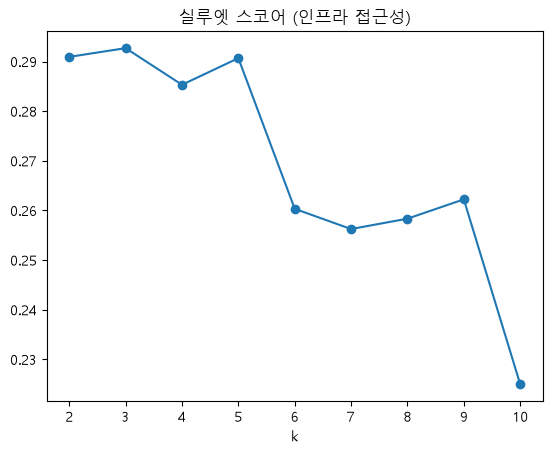

k=2: silhouette=0.2909
k=3: silhouette=0.2927
k=4: silhouette=0.2853
k=5: silhouette=0.2907
k=6: silhouette=0.2603
k=7: silhouette=0.2562
k=8: silhouette=0.2583
k=9: silhouette=0.2622
k=10: silhouette=0.2250


In [7]:
infra_cols = ["역세권거리_m", "초등학교거리_m", "중학교거리_m", "고등학교거리_m"]
df_cluster_infra = df_fe[infra_cols].dropna().copy()

scaler_infra = StandardScaler()
X_cluster_infra = scaler_infra.fit_transform(df_cluster_infra)

silhouette_list_infra = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_infra)
    silhouette_list_infra.append(silhouette_score(X_cluster_infra, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_infra, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (인프라 접근성)")
plt.show()

for k, s in zip(k_range, silhouette_list_infra):
    print(f"k={k}: silhouette={s:.4f}")


In [15]:
# 최종 군집화: 실루엣 최고점은 k=3(0.2927)이지만, k=3은 "역세권형"과 "학군형" 클러스터가 하나로 합쳐져
# 이 버전의 목적(교통 중심 vs 학군 중심 인프라 유형 구분)이 사라짐. k=5(0.2907, 최고점과 0.002 차이로 근접)는
# 그 구분을 유지하면서 강서구·중구 등 인프라 특이 지역을 별도 군집(원거리/특수 인프라형)으로 분리해내므로 k=5를 채택.
final_k_infra = 5
kmeans_c = KMeans(n_clusters=final_k_infra, random_state=42, n_init=10)
df_cluster_infra["cluster"] = kmeans_c.fit_predict(X_cluster_infra)

cluster_summary_c = df_cluster_infra.groupby("cluster")[infra_cols].mean().round(1)
cluster_summary_c["건수"] = df_cluster_infra["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_c = silhouette_score(X_cluster_infra, kmeans_c.labels_)
print(f"최종 k={final_k_infra} 전체 데이터 기준 실루엣 스코어: {final_sil_c:.4f}")

cluster_summary_c


최종 k=5 전체 데이터 기준 실루엣 스코어: 0.2893


,역세권거리_m,초등학교거리_m,중학교거리_m,고등학교거리_m,건수
cluster,,,,,
0,522.0,546.4,472.0,574.8,17053
1,600.5,315.5,833.6,783.7,14460
2,622.9,299.4,418.4,1145.8,9920
3,4910.6,376.9,548.9,858.3,3531
4,568.1,246.7,338.4,406.7,36256


In [16]:
df_fe.loc[df_cluster_infra.index, "cluster_infra"] = df_cluster_infra["cluster"].values

# 구별 분포 — 인프라 유형이 특정 지역에 몰리는지, 여러 지역에 걸쳐 있는지 확인
pd.crosstab(df_fe["시군구명"], df_fe["cluster_infra"])


cluster_infra,0.0,1.0,2.0,3.0,4.0
시군구명,,,,,
강남구,1164,474,110,0,1107
강동구,897,391,630,0,2080
강북구,232,159,88,0,1031
강서구,1170,362,852,1471,2498
관악구,736,496,72,0,1292
광진구,262,279,40,0,806
구로구,1245,846,699,0,1283
금천구,67,173,489,0,502
노원구,944,741,287,0,5488


각 클러스터의 4개 거리 평균을 비교해서, "역은 가깝지만 학교는 먼 곳", "역·학교 다 가까운 곳(올인프라)", "다 먼 곳" 같은 이름을 붙일 수 있습니다. 위 crosstab에서 특정 클러스터가 여러 구에 고르게 나타나면, 이는 "지역과 무관하게 존재하는 인프라 유형"이라는 뜻이라 마케팅/추천 활용도가 더 높습니다.

## 버전 C-1 — 역세권 단독

**피처**: `역세권거리_m`

버전 C(초·중·고·역세권을 합친 것)는 여러 거리 피처가 섞여 있어 "정확히 어떤 인프라가 영향을 줬는지" 해석이 어려웠습니다. 여기서는 역세권거리 하나만으로 군집화해서, 순수하게 교통 접근성만 기준으로 매물이 어떻게 나뉘는지 봅니다.

> 피처가 1차원이라 KMeans 군집이 사실상 "거리 구간을 몇 단계로 나누는 것"과 비슷한 의미를 가집니다. 그래도 사람이 임의로 구간을 정하는 것보다, 데이터 분포 자체가 갈리는 지점을 찾아준다는 점에서 의미가 있습니다.

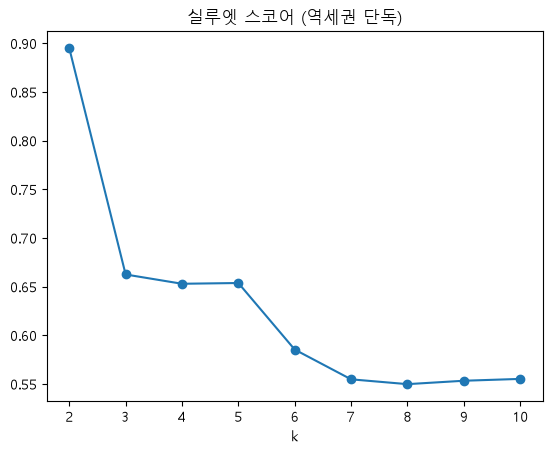

k=2: silhouette=0.8951
k=3: silhouette=0.6626
k=4: silhouette=0.6530
k=5: silhouette=0.6538
k=6: silhouette=0.5854
k=7: silhouette=0.5548
k=8: silhouette=0.5499
k=9: silhouette=0.5534
k=10: silhouette=0.5553


In [8]:
transit_cols = ["역세권거리_m"]
df_cluster_transit = df_fe[transit_cols].dropna().copy()

scaler_transit = StandardScaler()
X_cluster_transit = scaler_transit.fit_transform(df_cluster_transit)

silhouette_list_transit = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_transit)
    silhouette_list_transit.append(silhouette_score(X_cluster_transit, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_transit, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (역세권 단독)")
plt.show()

for k, s in zip(k_range, silhouette_list_transit):
    print(f"k={k}: silhouette={s:.4f}")


In [18]:
# 최종 군집화: k=4(0.653)에서는 "가까운" 클러스터가 0~793m를 통째로 묶어(평균 430m, 전체의 78%)
# 진짜 300m 이내 초역세권과 500~800m대 역세권이 구분되지 않았음 — 근거리 쪽 데이터가 촘촘히 몰려있어
# k=4 정도로는 세분화가 안 되고, 분리력은 대부분 소수의 원거리 이상치를 갈라내는 데만 쓰임.
# k=6(0.585, 큰 차이 없음)로 올리면 가장 가까운 클러스터가 평균 343m(29~544m, 56%)로 좁혀져
# "초역세권"이라 부를 만한 실제 근거리 구간이 나옴.
final_k_transit = 6
kmeans_transit = KMeans(n_clusters=final_k_transit, random_state=42, n_init=10)
df_cluster_transit["cluster"] = kmeans_transit.fit_predict(X_cluster_transit)

cluster_summary_transit = df_cluster_transit.groupby("cluster")[transit_cols].mean().round(1)
cluster_summary_transit["건수"] = df_cluster_transit["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_transit = silhouette_score(X_cluster_transit, kmeans_transit.labels_)
print(f"최종 k={final_k_transit} 전체 데이터 기준 실루엣 스코어: {final_sil_transit:.4f}")

cluster_summary_transit


최종 k=6 전체 데이터 기준 실루엣 스코어: 0.5815


,역세권거리_m,건수
cluster,,
0,343.2,45370
1,5328.8,1640
2,1539.1,5259
3,8569.9,317
4,748.3,26856
5,3647.1,1778


In [ ]:
df_fe.loc[df_cluster_transit.index, "cluster_transit"] = df_cluster_transit["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_transit"])


역세권거리 평균이 클러스터별로 뚜렷하게 계단식으로 나뉘는지 확인합니다 (예: 초역세권/역세권/준역세권/비역세권). 여러 구에 고르게 걸쳐 있다면, 역세권 여부가 지역 자체와 무관한 독립적인 축이라는 뜻입니다.

## 버전 C-2 — 초등학군 단독

**피처**: `초등학교거리_m`

자녀가 있는 가구가 특히 민감하게 보는 초등학교 접근성만 따로 봅니다.

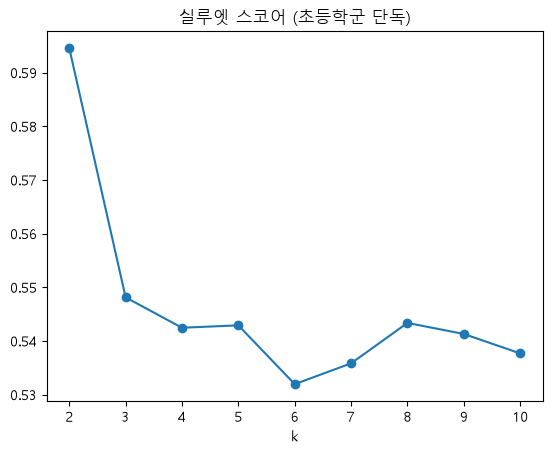

k=2: silhouette=0.5946
k=3: silhouette=0.5481
k=4: silhouette=0.5425
k=5: silhouette=0.5429
k=6: silhouette=0.5319
k=7: silhouette=0.5358
k=8: silhouette=0.5434
k=9: silhouette=0.5413
k=10: silhouette=0.5377


In [9]:
elem_cols = ["초등학교거리_m"]
df_cluster_elem = df_fe[elem_cols].dropna().copy()

scaler_elem = StandardScaler()
X_cluster_elem = scaler_elem.fit_transform(df_cluster_elem)

silhouette_list_elem = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_elem)
    silhouette_list_elem.append(silhouette_score(X_cluster_elem, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_elem, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (초등학군 단독)")
plt.show()

for k, s in zip(k_range, silhouette_list_elem):
    print(f"k={k}: silhouette={s:.4f}")


In [20]:
# 최종 군집화: 실루엣 최고점은 k=2(0.595, 34%/66%로 "학교 가까움 vs 멂"만 구분)이지만, 이러면
# "초품아"(초등학교를 품은 아파트) 같은 세분화된 구간을 볼 수 없음. k=4(0.543, 최고점과 근접)는
# 176m/315m/473m/693m로 계단식 구간이 뚜렷하게 나뉘어 마케팅 활용도가 더 높으므로 k=4를 채택.
final_k_elem = 4
kmeans_elem = KMeans(n_clusters=final_k_elem, random_state=42, n_init=10)
df_cluster_elem["cluster"] = kmeans_elem.fit_predict(X_cluster_elem)

cluster_summary_elem = df_cluster_elem.groupby("cluster")[elem_cols].mean().round(1)
cluster_summary_elem["건수"] = df_cluster_elem["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_elem = silhouette_score(X_cluster_elem, kmeans_elem.labels_)
print(f"최종 k={final_k_elem} 전체 데이터 기준 실루엣 스코어: {final_sil_elem:.4f}")

cluster_summary_elem


최종 k=4 전체 데이터 기준 실루엣 스코어: 0.5401


,초등학교거리_m,건수
cluster,,
0,693.1,6550
1,176.6,27974
2,472.7,18715
3,314.4,27981


In [21]:
df_fe.loc[df_cluster_elem.index, "cluster_elem"] = df_cluster_elem["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_elem"])


cluster_elem,0.0,1.0,2.0,3.0
시군구명,,,,
강남구,463,551,864,977
강동구,423,1368,702,1505
강북구,59,305,355,791
강서구,502,2422,1572,1857
관악구,120,796,853,827
광진구,59,478,284,566
구로구,192,1209,1283,1389
금천구,35,556,248,392
노원구,75,3431,1284,2670


거리가 가장 짧은 클러스터(초품아 — 초등학교를 품은 아파트)가 특정 구에 몰려 있는지, 여러 구에 흩어져 있는지 확인합니다. 흩어져 있다면 "초품아 매물 스크리닝"을 지역과 무관하게 전체 서울 기준으로 제공할 수 있다는 뜻입니다.

In [22]:
df_fe[["초등학교거리_m", "역세권거리_m", "log_price"]].corr()


,초등학교거리_m,역세권거리_m,log_price
초등학교거리_m,1.000000,0.035340,-0.032313
역세권거리_m,0.035340,1.000000,-0.332298
log_price,-0.032313,-0.332298,1.000000


**검증 결과**: 초등학교거리와 가격의 상관계수는 **-0.032**로 사실상 무관합니다. 비교를 위해 함께 넣은 역세권거리는 **-0.332**로 뚜렷한 음의 상관관계를 보여, 같은 "위치 접근성" 피처 안에서도 성격이 전혀 다릅니다.

서울은 초등학교 밀도가 높고 학군에 관계없이 고르게 분포해 있어, "거리"만으로는 초등학군의 핵심 가치(배정 학교의 질 등)를 포착하지 못하는 것으로 보입니다. 즉 이 군집은 **가격 예측용이 아니라, "초품아 여부" 같은 생활 편의 정보를 태깅하는 용도**로 포지셔닝하는 게 맞습니다 — 자녀가 있는 가구에게는 여전히 유의미한 정보이기 때문입니다.

## 버전 C-3 — 중고등학군

**피처**: `중학교거리_m`, `고등학교거리_m`

중·고등학교는 입시와 직결되는 학군 개념(예: 대치동, 목동)과 더 밀접하다고 알려져 있어, 초등학군과 분리해서 봅니다.

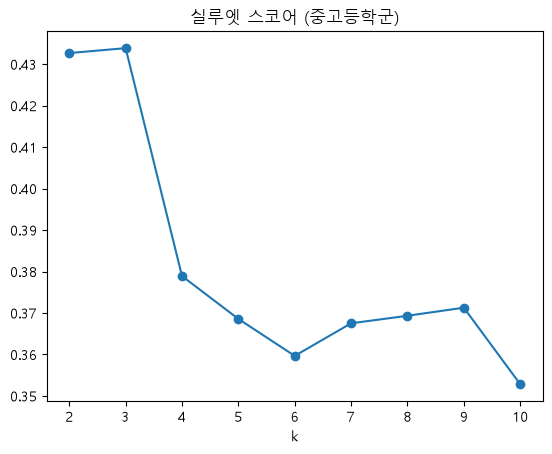

k=2: silhouette=0.4327
k=3: silhouette=0.4339
k=4: silhouette=0.3789
k=5: silhouette=0.3686
k=6: silhouette=0.3597
k=7: silhouette=0.3675
k=8: silhouette=0.3693
k=9: silhouette=0.3713
k=10: silhouette=0.3528


In [10]:
secondary_cols = ["중학교거리_m", "고등학교거리_m"]
df_cluster_secondary = df_fe[secondary_cols].dropna().copy()

scaler_secondary = StandardScaler()
X_cluster_secondary = scaler_secondary.fit_transform(df_cluster_secondary)

silhouette_list_secondary = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_secondary)
    silhouette_list_secondary.append(silhouette_score(X_cluster_secondary, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_secondary, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (중고등학군)")
plt.show()

for k, s in zip(k_range, silhouette_list_secondary):
    print(f"k={k}: silhouette={s:.4f}")


In [ ]:
# 최종 군집화 (실루엣 스코어 최고점 k=3=0.434 채택. 기존 k=4=0.379보다 뚜렷이 높고,
# 26%/59%/15%로 균형 잡힌 3분할 — "둘다 멂/둘다 가까움(학군우수)/중학교만 가까움" 으로 해석 가능해 k=4보다 오히려 더 명확함)
final_k_secondary = 3
kmeans_secondary = KMeans(n_clusters=final_k_secondary, random_state=42, n_init=10)
df_cluster_secondary["cluster"] = kmeans_secondary.fit_predict(X_cluster_secondary)

cluster_summary_secondary = df_cluster_secondary.groupby("cluster")[secondary_cols].mean().round(1)
cluster_summary_secondary["건수"] = df_cluster_secondary["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_secondary = silhouette_score(X_cluster_secondary, kmeans_secondary.labels_)
print(f"최종 k={final_k_secondary} 전체 데이터 기준 실루엣 스코어: {final_sil_secondary:.4f}")

cluster_summary_secondary


In [ ]:
df_fe.loc[df_cluster_secondary.index, "cluster_secondary"] = df_cluster_secondary["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_secondary"])


중학교거리와 고등학교거리가 같이 짧은 클러스터(중고등 학군 밀집지)가 특정 구(예: 강남·양천·노원 등 전통적 학군지)에 몰려 나오는지 확인합니다. 초등학군(C-2) 결과와 비교했을 때 지역 분포가 다르게 나온다면, "초등학군 좋은 곳"과 "중고등학군 좋은 곳"이 반드시 일치하지 않는다는 흥미로운 시사점이 됩니다.

In [ ]:
df_fe[["중학교거리_m", "고등학교거리_m", "log_price"]].corr()


**검증 결과**: 중학교거리(r=-0.048), 고등학교거리(r=-0.102) 모두 가격과 거의 무관합니다.

직관적으로는 "학군 좋은 곳 = 비싼 곳"일 것 같지만, 강남 8학군 같은 학군 프리미엄은 "학교가 가까워서"가 아니라 "그 학교의 학업성취도·명문고 진학률이 높아서"이며, 이는 물리적 거리로는 전혀 측정되지 않습니다. 오히려 초고가 저밀도 주거지는 학교 자체가 드물어 거리가 먼 경우도 있어, 상관관계가 약하거나 방향이 불안정하게 나타날 수 있습니다.

**결론**: 위치 기반 인프라 접근성 3종(역세권·초등학교·중고등학교 거리)을 가격과의 상관관계로 비교하면, **역세권거리만 뚜렷한 관계(r=-0.33)를 보이고 학군 관련 거리는 전부 무관(|r|<0.11)**합니다. 이는 회귀 모델(`04_regression`)에서 역세권거리 추가 시 R²가 크게 개선(0.89→0.93)됐던 것과 일치하는 결과이며, 학군거리 피처는 회귀보다는 **군집을 통한 매물 특징 태깅("초품아만 보기" 등 스크리닝 필터)** 용도로 활용하는 것이 적합합니다.

## 버전 D — 가격·평형 소비자 세그먼트

**피처**: `log_price`, `전용면적`, `평당가`

지역이나 인프라 없이, 순수하게 "얼마짜리를, 얼마나 큰 평수를, 평당 얼마에" 사는지로 군집화합니다. 목적은 소비자 관점에서 "이 매물은 어떤 고객층에 맞는가"를 구분하는 것입니다 (예: 신혼부부용 소형 저가 / 중산층 중형 / 자산가용 대형 고가).

> 탐색 단계에서는 `sample_size=5000`으로 실루엣 스코어를 근사 계산해 속도를 확보하고, 최종 선택된 k에 대해서만 전체 데이터로 한 번 더 정확히 검증합니다 (전체 데이터 실루엣 계산은 O(n²)이라 8만 건 규모에서는 k 하나당도 시간이 걸릴 수 있습니다).

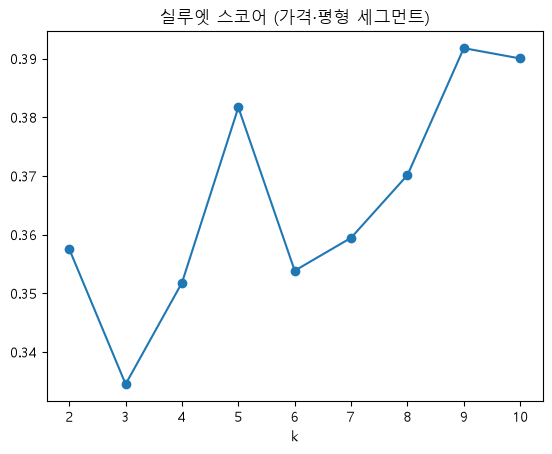

k=2: silhouette=0.3575
k=3: silhouette=0.3345
k=4: silhouette=0.3518
k=5: silhouette=0.3817
k=6: silhouette=0.3538
k=7: silhouette=0.3594
k=8: silhouette=0.3701
k=9: silhouette=0.3918
k=10: silhouette=0.3900


In [11]:
segment_cols = ["log_price", "전용면적", "log_평당가"]
# 원본 평당가는 군집 피처엔 안 쓰지만, 결과 해석(요약표)에서 보여주기 위해 같이 보관
df_cluster_segment = df_fe[segment_cols + ["평당가"]].dropna().copy()

scaler_segment = StandardScaler()
X_cluster_segment = scaler_segment.fit_transform(df_cluster_segment[segment_cols])

silhouette_list_segment = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_segment)
    silhouette_list_segment.append(silhouette_score(X_cluster_segment, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_segment, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (가격·평형 세그먼트)")
plt.show()

for k, s in zip(k_range, silhouette_list_segment):
    print(f"k={k}: silhouette={s:.4f}")


In [ ]:
# 최종 군집화: 실루엣 스코어 자체는 k=9(0.392)에서 가장 높지만 9개 세그먼트는 "신혼부부용 소형" 같은
# 마케팅 페르소나로 쓰기엔 너무 잘게 쪼개짐. k=5(0.382, 최고점과 거의 차이 없음)는 5개 그룹이 크기도
# 균등(7~29%)하고 가격·평형·평당가 조합이 뚜렷이 구분되는 소비자 세그먼트로 해석되므로 k=5를 채택.
final_k_segment = 5
kmeans_d = KMeans(n_clusters=final_k_segment, random_state=42, n_init=10)
df_cluster_segment["cluster"] = kmeans_d.fit_predict(X_cluster_segment)

df_cluster_segment["거래금액_복원"] = np.expm1(df_cluster_segment["log_price"])
summary_cols_segment = ["거래금액_복원", "전용면적", "평당가"]  # 해석 편의를 위해 원본 평당가로 표시
cluster_summary_d = df_cluster_segment.groupby("cluster")[summary_cols_segment].mean().round(1)
cluster_summary_d["건수"] = df_cluster_segment["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_d = silhouette_score(X_cluster_segment, kmeans_d.labels_)
print(f"최종 k={final_k_segment} 전체 데이터 기준 실루엣 스코어: {final_sil_d:.4f}")

cluster_summary_d


In [ ]:
df_fe.loc[df_cluster_segment.index, "cluster_segment"] = df_cluster_segment["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_segment"])


`cluster_summary_d`의 거래금액·전용면적·평당가 조합을 보고 "신혼부부용 소형", "실수요 중형", "자산가용 대형" 같은 이름을 붙일 수 있습니다. 이 라벨은 회귀·분류보다 오히려 **영업/마케팅 세그먼트**로 바로 쓸 수 있다는 점에서 실용성이 높습니다 — 예: 웹서비스에서 "어떤 예산대의 고객이신가요?" 필터로 노출.

## 버전 E — 가격 대비 인프라 (투자 매력도)

**피처**: `평당가`, `연식`, `역세권거리_m`, `초등학교거리_m`

"가격은 낮은데 인프라는 좋은" 지역/매물군을 찾기 위한 군집입니다. 평당가가 낮으면서 역·학교 거리가 짧은 클러스터가 있다면, 이는 아직 가격에 인프라 프리미엄이 충분히 반영되지 않은 **잠재 저평가군**일 수 있습니다. 05(분류)의 저평가 스크리닝과 연결되는 관점입니다.

> 탐색 단계에서는 `sample_size=5000`으로 실루엣 스코어를 근사 계산해 속도를 확보하고, 최종 선택된 k에 대해서만 전체 데이터로 한 번 더 정확히 검증합니다 (전체 데이터 실루엣 계산은 O(n²)이라 8만 건 규모에서는 k 하나당도 시간이 걸릴 수 있습니다).

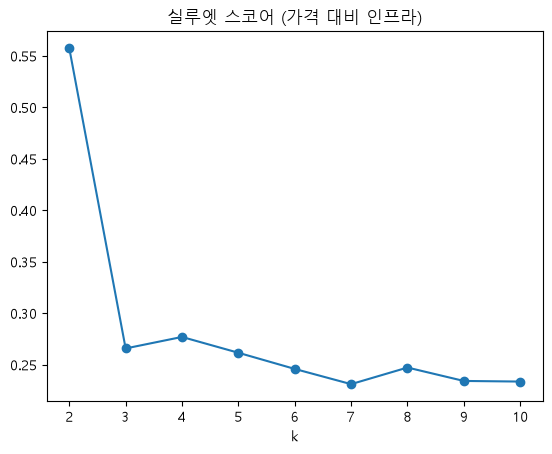

k=2: silhouette=0.5576
k=3: silhouette=0.2659
k=4: silhouette=0.2770
k=5: silhouette=0.2617
k=6: silhouette=0.2460
k=7: silhouette=0.2312
k=8: silhouette=0.2473
k=9: silhouette=0.2343
k=10: silhouette=0.2337


In [12]:
value_cols = ["log_평당가", "연식", "역세권거리_m", "초등학교거리_m"]
# 원본 평당가는 군집 피처엔 안 쓰지만, 결과 해석(요약표)에서 보여주기 위해 같이 보관
df_cluster_value = df_fe[value_cols + ["평당가"]].dropna().copy()

scaler_value = StandardScaler()
X_cluster_value = scaler_value.fit_transform(df_cluster_value[value_cols])

silhouette_list_value = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_value)
    silhouette_list_value.append(silhouette_score(X_cluster_value, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_value, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (가격 대비 인프라)")
plt.show()

for k, s in zip(k_range, silhouette_list_value):
    print(f"k={k}: silhouette={s:.4f}")


In [ ]:
# 최종 군집화: 실루엣 최고점은 k=2(0.558)이지만 95%/5%로 갈리는 "역세권에서 극단적으로 먼 이상치"
# 분리일 뿐, 저평가 지역 스크리닝이라는 목적에는 쓸모가 없음. 이상치 분할을 제외한 범위에서는
# k=4(0.277)가 최고점이라 k=4를 채택.
final_k_value = 4
kmeans_e = KMeans(n_clusters=final_k_value, random_state=42, n_init=10)
df_cluster_value["cluster"] = kmeans_e.fit_predict(X_cluster_value)

# 해석 편의를 위해 log_평당가 대신 원본 평당가로 요약 표시
value_summary_cols = [c if c != "log_평당가" else "평당가" for c in value_cols]
cluster_summary_e = df_cluster_value.groupby("cluster")[value_summary_cols].mean().round(1)
cluster_summary_e["건수"] = df_cluster_value["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_e = silhouette_score(X_cluster_value, kmeans_e.labels_)
print(f"최종 k={final_k_value} 전체 데이터 기준 실루엣 스코어: {final_sil_e:.4f}")

cluster_summary_e


In [ ]:
df_fe.loc[df_cluster_value.index, "cluster_value"] = df_cluster_value["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_value"])


`cluster_summary_e`에서 **평당가는 낮은데 역세권거리·초등학교거리도 짧은 클러스터**가 있는지 확인합니다. 있다면 그 클러스터에 속한 구/단지를 "가격 대비 인프라가 좋은 잠재 저평가 지역"으로 별도 리스트업할 수 있습니다.

In [ ]:
# (참고) 평당가 대비 인프라가 유독 좋은 클러스터 찾기 — 평당가 오름차순, 거리 합 오름차순으로 정렬해서 눈으로 확인
cluster_summary_e.assign(
    거리합=cluster_summary_e["역세권거리_m"] + cluster_summary_e["초등학교거리_m"]
).sort_values(["평당가", "거리합"])  # 평당가는 원본 스케일로 표시되어 있어 그대로 정렬 사용


## 버전 F — 위치 프리미엄 세그먼트 (역세권거리 + 평형 + 가격)

**피처**: `역세권거리_m`, `전용면적`, `log_price`

C-1(역세권 단독)은 "거리"만 봐서, 같은 344m 지점의 매물이 소형인지 대형인지, 저가인지 고가인지는 구분하지 못했습니다. 상관관계 검증(`역세권거리_m` vs `log_price`, r=-0.33)에서 역세권거리가 실제로 가격과 연동된다는 게 확인됐으니, 여기에 평형·가격을 더해 "역세권 + 어떤 조건" 조합의 세그먼트가 나오는지 봅니다 (예: 역세권 소형 오피스텔형 vs 역세권 대단지 프리미엄).

> 탐색 단계에서는 `sample_size=5000`으로 실루엣 스코어를 근사 계산해 속도를 확보하고, 최종 선택된 k에 대해서만 전체 데이터로 한 번 더 정확히 검증합니다.

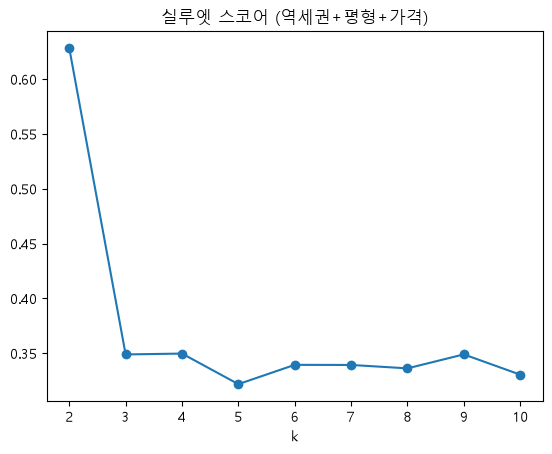

k=2: silhouette=0.6283
k=3: silhouette=0.3490
k=4: silhouette=0.3498
k=5: silhouette=0.3219
k=6: silhouette=0.3395
k=7: silhouette=0.3394
k=8: silhouette=0.3363
k=9: silhouette=0.3490
k=10: silhouette=0.3306


In [13]:
transit_price_cols = ["역세권거리_m", "전용면적", "log_price"]
df_cluster_transit_price = df_fe[transit_price_cols].dropna().copy()

scaler_transit_price = StandardScaler()
X_cluster_transit_price = scaler_transit_price.fit_transform(df_cluster_transit_price)

silhouette_list_transit_price = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_transit_price)
    silhouette_list_transit_price.append(silhouette_score(X_cluster_transit_price, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_transit_price, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (역세권+평형+가격)")
plt.show()

for k, s in zip(k_range, silhouette_list_transit_price):
    print(f"k={k}: silhouette={s:.4f}")


In [ ]:
# 최종 군집화 (위 실루엣 스코어 그래프 보고 k 직접 지정)
final_k_transit_price = 5
kmeans_f = KMeans(n_clusters=final_k_transit_price, random_state=42, n_init=10)
df_cluster_transit_price["cluster"] = kmeans_f.fit_predict(X_cluster_transit_price)

df_cluster_transit_price["거래금액_복원"] = np.expm1(df_cluster_transit_price["log_price"])
summary_cols_f = ["역세권거리_m", "전용면적", "거래금액_복원"]
cluster_summary_f = df_cluster_transit_price.groupby("cluster")[summary_cols_f].mean().round(1)
cluster_summary_f["건수"] = df_cluster_transit_price["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_f = silhouette_score(X_cluster_transit_price, kmeans_f.labels_)
print(f"최종 k={final_k_transit_price} 전체 데이터 기준 실루엣 스코어: {final_sil_f:.4f}")

cluster_summary_f.sort_values("역세권거리_m")


In [ ]:
df_fe.loc[df_cluster_transit_price.index, "cluster_transit_price"] = df_cluster_transit_price["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_transit_price"])


`cluster_summary_f`를 역세권거리 기준으로 정렬해서 확인합니다. "역세권 초근접+소형+고가"(1인가구 역세권 프리미엄), "역세권 원거리+대형+중가"(외곽 대단지) 같은 조합이 뚜렷이 나뉘는지가 핵심입니다. crosstab에서 특정 세그먼트가 여러 구에 고르게 나타나면, 지역과 무관하게 통용되는 위치 프리미엄 세그먼트로 활용할 수 있습니다.

## 버전 G — 재건축 후보군 (연식 × 층)

**피처**: `연식`, `층`

재건축 대상 아파트는 통상 연식이 오래됐으면서 용적률이 낮은 저층 단지인 경우가 많습니다. "오래됐으면서 저층"인 매물군이 따로 묶이는지 확인해, 재건축 기대감이 있는 매물 스크리닝에 활용할 수 있는지 봅니다.

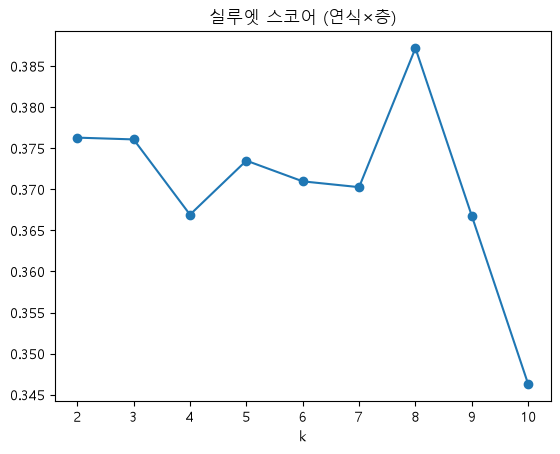

k=2: silhouette=0.3763
k=3: silhouette=0.3761
k=4: silhouette=0.3669
k=5: silhouette=0.3735
k=6: silhouette=0.3710
k=7: silhouette=0.3703
k=8: silhouette=0.3872
k=9: silhouette=0.3668
k=10: silhouette=0.3463


In [14]:
redevelop_cols = ["연식", "층"]
df_cluster_redevelop = df_fe[redevelop_cols].dropna().copy()

scaler_redevelop = StandardScaler()
X_cluster_redevelop = scaler_redevelop.fit_transform(df_cluster_redevelop)

silhouette_list_redevelop = []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_redevelop)
    silhouette_list_redevelop.append(silhouette_score(X_cluster_redevelop, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_redevelop, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (연식×층)")
plt.show()

for k, s in zip(k_range, silhouette_list_redevelop):
    print(f"k={k}: silhouette={s:.4f}")


In [ ]:
# 최종 군집화 (위 실루엣 스코어 그래프 보고 k 직접 지정)
final_k_redevelop = 4
kmeans_g = KMeans(n_clusters=final_k_redevelop, random_state=42, n_init=10)
df_cluster_redevelop["cluster"] = kmeans_g.fit_predict(X_cluster_redevelop)

cluster_summary_g = df_cluster_redevelop.groupby("cluster")[redevelop_cols].mean().round(1)
cluster_summary_g["건수"] = df_cluster_redevelop["cluster"].value_counts().sort_index()

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_g = silhouette_score(X_cluster_redevelop, kmeans_g.labels_)
print(f"최종 k={final_k_redevelop} 전체 데이터 기준 실루엣 스코어: {final_sil_g:.4f}")

cluster_summary_g.sort_values("연식", ascending=False)


In [ ]:
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    df_cluster_redevelop["연식"], df_cluster_redevelop["층"],
    c=df_cluster_redevelop["cluster"], cmap="tab10", alpha=0.3, s=8,
)
plt.xlabel("연식")
plt.ylabel("층")
plt.title("버전 G 클러스터 — 연식 vs 층")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.tight_layout()
plt.show()


In [ ]:
df_fe.loc[df_cluster_redevelop.index, "cluster_redevelop"] = df_cluster_redevelop["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_redevelop"])


`cluster_summary_g`를 연식 내림차순으로 정렬해서, "연식이 가장 높으면서(오래됐으면서) 층이 낮은" 클러스터가 있는지 확인합니다. 있다면 이 클러스터를 "재건축 기대 매물군"으로 05(분류)의 저평가 스크리닝과 함께 태깅할 수 있습니다. 다만 이 군집은 실제 재건축 승인·안전진단 등급 등 공식 절차 정보를 전혀 반영하지 못한, 순수 통계적 추정이라는 한계가 있습니다.

## 버전 H — 거래유형별 패턴 (직거래 vs 중개거래)

**피처**: `거래유형`(원-핫), `log_price`, `전용면적`

지금까지 한 번도 쓰지 않은 `거래유형`(직거래/중개거래) 필드를 확인합니다. 직거래는 지인 간 거래 등으로 시세보다 낮게 신고되는 경우가 있다고 알려져 있는데, 실제 데이터에서 가격 패턴에 차이가 있는지 먼저 분포로 확인한 뒤 군집화합니다.

In [ ]:
print(df_fe["거래유형"].value_counts(dropna=False))


In [ ]:
df_fe.groupby("거래유형")[price_col].describe()


위 두 표를 먼저 확인합니다. 직거래 비중이 매우 작거나(예: 1% 미만), 가격 분포에 뚜렷한 차이가 없다면 아래 군집화는 의미가 적을 수 있습니다. 차이가 보인다면 이어서 군집으로 패턴을 확인합니다.

In [ ]:
deal_type_cols = ["log_price", "전용면적"]
df_cluster_dealtype = df_fe[deal_type_cols + ["거래유형"]].dropna().copy()
df_cluster_dealtype_encoded = pd.get_dummies(df_cluster_dealtype, columns=["거래유형"])

scaler_dealtype = StandardScaler()
X_cluster_dealtype = scaler_dealtype.fit_transform(df_cluster_dealtype_encoded)

silhouette_list_dealtype = []
k_range = range(2, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_dealtype)
    silhouette_list_dealtype.append(silhouette_score(X_cluster_dealtype, labels, sample_size=5000, random_state=42))

plt.plot(list(k_range), silhouette_list_dealtype, marker="o")
plt.xlabel("k")
plt.title("실루엣 스코어 (거래유형+가격+평형)")
plt.show()

for k, s in zip(k_range, silhouette_list_dealtype):
    print(f"k={k}: silhouette={s:.4f}")


In [ ]:
# 최종 군집화 (위 실루엣 스코어 그래프 보고 k 직접 지정)
final_k_dealtype = 4
kmeans_h = KMeans(n_clusters=final_k_dealtype, random_state=42, n_init=10)
df_cluster_dealtype_encoded["cluster"] = kmeans_h.fit_predict(X_cluster_dealtype)

df_cluster_dealtype_encoded["거래금액_복원"] = np.expm1(df_cluster_dealtype_encoded["log_price"])

# 최종 선택된 k에 대해 전체 데이터로 실루엣 스코어 재검증 (시간이 걸릴 수 있음)
final_sil_h = silhouette_score(X_cluster_dealtype, kmeans_h.labels_)
print(f"최종 k={final_k_dealtype} 전체 데이터 기준 실루엣 스코어: {final_sil_h:.4f}")

# 클러스터별로 거래유형 구성비 확인 (원-핫 컬럼 평균 = 해당 유형 비율)
dealtype_onehot_cols = [c for c in df_cluster_dealtype_encoded.columns if c.startswith("거래유형_")]
cluster_summary_h = df_cluster_dealtype_encoded.groupby("cluster")[["거래금액_복원", "전용면적"] + dealtype_onehot_cols].mean().round(3)
cluster_summary_h["건수"] = df_cluster_dealtype_encoded["cluster"].value_counts().sort_index()
cluster_summary_h


In [ ]:
df_fe.loc[df_cluster_dealtype_encoded.index, "cluster_dealtype"] = df_cluster_dealtype_encoded["cluster"].values

pd.crosstab(df_fe["시군구명"], df_fe["cluster_dealtype"])


`cluster_summary_h`에서 특정 클러스터의 "거래유형_직거래"(또는 실제 컬럼명) 비율이 다른 클러스터보다 뚜렷이 높은지, 그리고 그 클러스터의 거래금액이 유의미하게 낮은지 확인합니다. 그렇다면 "일부 직거래가 시세보다 낮게 신고되는 경향"이 통계적으로 뒷받침되는 것이고, 이 경우 데이터를 제거하기보다 회귀·분류 모델에 `거래유형` 자체를 피처로 추가해 이 편차를 학습하게 하는 방향을 권장합니다. 차이가 없다면 이 필드는 가격 예측에 큰 영향이 없다고 결론짓고 넘어갑니다.

## 고도화 — GaussianMixture(GMM) 비교 및 시각화

KMeans는 모든 클러스터를 원형(구형)으로 가정하고 각 데이터를 **하나의 클러스터에 확정적으로** 배정합니다. **GaussianMixture(GMM)**은 클러스터를 타원형(공분산 구조)으로 유연하게 모델링하고, 각 데이터가 여러 클러스터에 속할 **확률(soft assignment)**을 함께 제공합니다.

부동산 매물은 "완전히 소형이다/중형이다"처럼 딱 잘라지지 않고 경계가 흐릿한 경우가 많아서(예: 33평인데 가격은 중형과 대형 사이), GMM의 확률적 배정이 실제로 더 현실적인 정보를 줄 수 있습니다. 여기서는 **버전 B(지역 제외, 신축소형 vs 일반구축 발견)**를 사례로 KMeans와 GMM을 비교합니다.

In [ ]:
from sklearn.metrics import silhouette_score

# GMM은 공분산 구조(covariance_type)에 따라 클러스터 모양 가정이 달라짐
# full: 각 클러스터가 독립적인 타원 모양 / tied: 모든 클러스터가 같은 모양 공유
# diag: 축에 평행한 타원 / spherical: KMeans와 유사한 구형
cov_types = ["full", "tied", "diag", "spherical"]
k_range_gmm = range(2, 8)

gmm_results = []
for cov_type in cov_types:
    for k in k_range_gmm:
        gmm = GaussianMixture(n_components=k, covariance_type=cov_type, random_state=42, n_init=3)
        labels = gmm.fit_predict(X_cluster_pure)
        sil = silhouette_score(X_cluster_pure, labels, sample_size=5000, random_state=42)  # 탐색 단계라 샘플링
        bic = gmm.bic(X_cluster_pure)
        gmm_results.append({"covariance_type": cov_type, "k": k, "silhouette": sil, "BIC": bic})

gmm_results_df = pd.DataFrame(gmm_results)
gmm_results_df.sort_values("BIC").head(10)


**BIC(베이지안 정보기준)**는 낮을수록 좋은 모델입니다 — 데이터를 잘 설명하면서도 과도하게 복잡하지 않은 모델을 골라줍니다. 실루엣 스코어(군집 분리도)와 BIC(모델 적합도)를 같이 보고 최적 조합(`covariance_type`, `k`)을 선택합니다.

In [ ]:
# BIC만 보고 고르면 full 공분산 + k=7처럼 컴포넌트를 지나치게 잘게 쪼개는(사실상 과적합) 모델이
# 뽑힐 수 있다 — 실제로 계산해보면 이 조합은 BIC는 가장 낮지만 실루엣은 0.02까지 떨어져 군집 분리가
# 사실상 실패한 상태다. KMeans(B)의 분리도(전체 데이터 기준 0.23)에 근접한 후보만 남기고
# 그중 BIC가 가장 낮은 조합을 선택한다.
sil_threshold = 0.2
candidates = gmm_results_df[gmm_results_df["silhouette"] >= sil_threshold]
best_gmm_row = candidates.loc[candidates["BIC"].idxmin()]
print(f"실루엣 >= {sil_threshold} 후보 중 BIC 기준 최적 조합:", dict(best_gmm_row))

best_cov_type = best_gmm_row["covariance_type"]
best_k_gmm = int(best_gmm_row["k"])

gmm_final = GaussianMixture(n_components=best_k_gmm, covariance_type=best_cov_type, random_state=42, n_init=3)
gmm_labels = gmm_final.fit_predict(X_cluster_pure)
gmm_proba = gmm_final.predict_proba(X_cluster_pure)  # 각 클러스터에 속할 확률

df_cluster_pure_gmm = df_cluster_pure.copy()
df_cluster_pure_gmm["cluster_gmm"] = gmm_labels
df_cluster_pure_gmm["거래금액_복원"] = np.expm1(df_cluster_pure_gmm["log_price"])

summary_cols = ["전용면적", "층", "연식", "거래금액_복원"]
cluster_summary_gmm = df_cluster_pure_gmm.groupby("cluster_gmm")[summary_cols].mean().round(1)
cluster_summary_gmm["건수"] = df_cluster_pure_gmm["cluster_gmm"].value_counts().sort_index()
cluster_summary_gmm


### KMeans vs GMM 비교

In [ ]:
# 최종 비교이므로 전체 데이터 기준으로 계산 (시간이 걸릴 수 있음)
kmeans_sil = silhouette_score(X_cluster_pure, kmeans_b.labels_)
gmm_sil = silhouette_score(X_cluster_pure, gmm_labels)

comparison = pd.DataFrame([
    {"model": f"KMeans (k={final_k_pure})", "실루엣 스코어": round(kmeans_sil, 4), "클러스터 수": final_k_pure},
    {"model": f"GMM ({best_cov_type}, k={best_k_gmm})", "실루엣 스코어": round(gmm_sil, 4), "클러스터 수": best_k_gmm},
])
comparison


### 소프트 배정(soft assignment) 활용 예시

GMM은 각 매물이 클러스터에 속할 확률을 주기 때문에, "경계에 있는 매물"을 찾아낼 수 있습니다. 예를 들어 어느 클러스터에도 60% 미만 확률로만 속하는 매물은, 두 유형의 특성을 동시에 가진 **혼합형 매물**로 해석할 수 있습니다 — 이런 매물은 스크리닝 시 별도로 표시하면 유용합니다.

In [ ]:
max_proba = gmm_proba.max(axis=1)
df_cluster_pure_gmm["최대소속확률"] = max_proba

ambiguous_ratio = (max_proba < 0.6).mean()
print(f"어느 클러스터에도 60% 미만으로만 속하는 '경계 매물' 비율: {ambiguous_ratio:.1%}")

df_cluster_pure_gmm.sort_values("최대소속확률").head(5)


## 고도화 — PCA로 클러스터 시각화

지금까지의 군집은 3~5차원 공간에서 이뤄져서 눈으로 직접 볼 수 없습니다. **PCA(주성분분석)**로 2차원에 투영해서, 클러스터들이 실제로 잘 분리되어 보이는지 시각적으로 확인합니다 (버전 B, KMeans 결과 기준).

2개 주성분이 설명하는 분산 비율: 69.0%


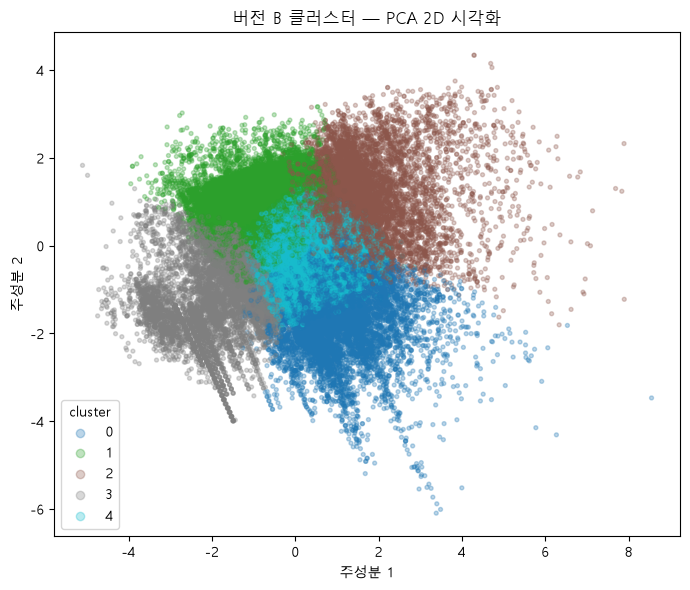

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster_pure)

print(f"2개 주성분이 설명하는 분산 비율: {pca.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_b.labels_, cmap="tab10", alpha=0.3, s=8)
plt.xlabel("주성분 1")
plt.ylabel("주성분 2")
plt.title("버전 B 클러스터 — PCA 2D 시각화")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.tight_layout()
plt.show()


## 고도화 참고 — 다른 버전(A/C/C-1/C-2/C-3/D/E)에도 같은 방식 적용

GMM·BIC 선택은 대표 사례로 버전 B에만 적용했고, PCA·분포 시각화는 아래에서 나머지 모든 버전에 적용합니다. 이미 2차원 이하인 C-1/C-2/C-3은 PCA 없이 원본 축(박스플롯·산점도)으로 바로 확인합니다.


2개 주성분이 설명하는 분산 비율: 12.3%


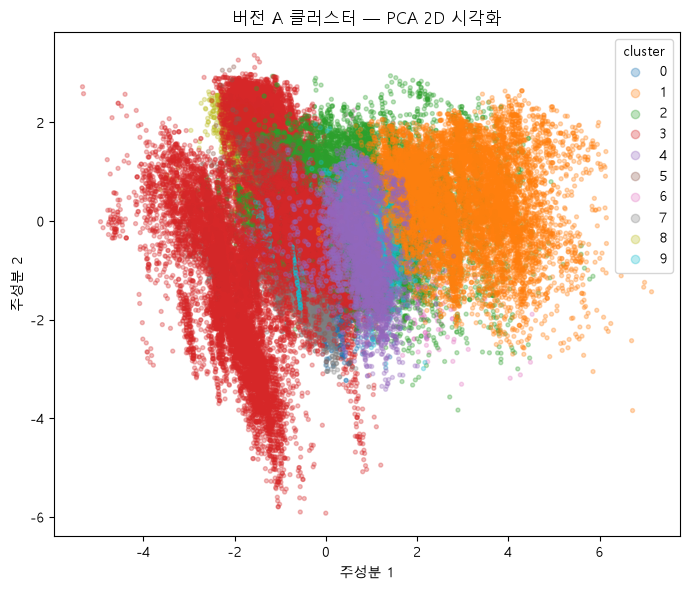

In [ ]:
# 버전 A — PCA 2D 시각화 (지역 원-핫이 포함되어 있어 대부분의 분산은 "어느 구인가"에서 옴)
pca_a = PCA(n_components=2, random_state=42)
X_pca_a = pca_a.fit_transform(X_cluster)
print(f"2개 주성분이 설명하는 분산 비율: {pca_a.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_pca_a[:, 0], X_pca_a[:, 1], c=kmeans_a.labels_, cmap="tab10", alpha=0.3, s=8)
plt.xlabel("주성분 1")
plt.ylabel("주성분 2")
plt.title("버전 A 클러스터 — PCA 2D 시각화")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.tight_layout()
plt.show()


2개 주성분이 설명하는 분산 비율: 62.8%


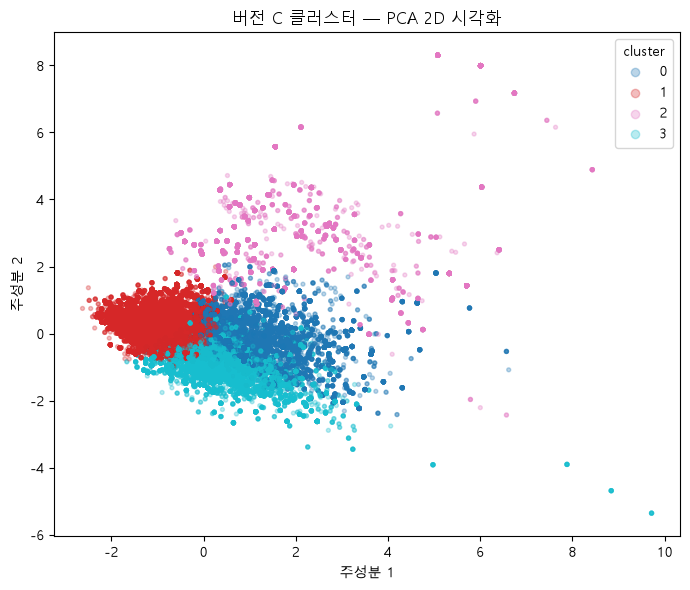

In [ ]:
# 버전 C — PCA 2D 시각화 (역세권거리·초/중/고 거리 4개 피처)
pca_c = PCA(n_components=2, random_state=42)
X_pca_c = pca_c.fit_transform(X_cluster_infra)
print(f"2개 주성분이 설명하는 분산 비율: {pca_c.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_pca_c[:, 0], X_pca_c[:, 1], c=kmeans_c.labels_, cmap="tab10", alpha=0.3, s=8)
plt.xlabel("주성분 1")
plt.ylabel("주성분 2")
plt.title("버전 C 클러스터 — PCA 2D 시각화")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.tight_layout()
plt.show()


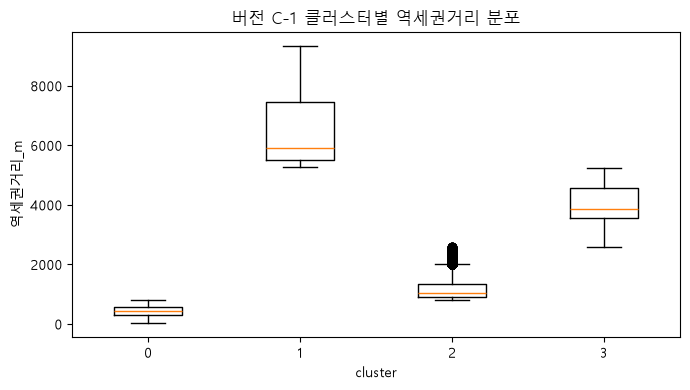

In [ ]:
# 버전 C-1 — 클러스터별 역세권거리 분포 (1차원 피처라 PCA 대신 박스플롯으로 확인)
fig, ax = plt.subplots(figsize=(7, 4))
cluster_ids = sorted(df_cluster_transit["cluster"].unique())
ax.boxplot(
    [df_cluster_transit.loc[df_cluster_transit["cluster"] == c, "역세권거리_m"] for c in cluster_ids],
)
ax.set_xticks(range(1, len(cluster_ids) + 1))
ax.set_xticklabels(cluster_ids)
ax.set_xlabel("cluster")
ax.set_ylabel("역세권거리_m")
ax.set_title("버전 C-1 클러스터별 역세권거리 분포")
plt.tight_layout()
plt.show()


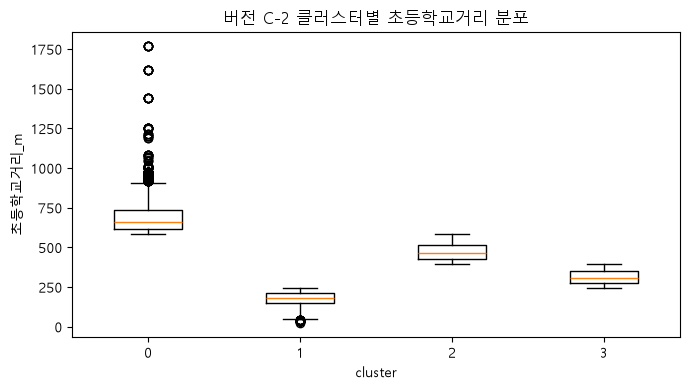

In [ ]:
# 버전 C-2 — 클러스터별 초등학교거리 분포 (1차원 피처라 PCA 대신 박스플롯으로 확인)
fig, ax = plt.subplots(figsize=(7, 4))
cluster_ids = sorted(df_cluster_elem["cluster"].unique())
ax.boxplot(
    [df_cluster_elem.loc[df_cluster_elem["cluster"] == c, "초등학교거리_m"] for c in cluster_ids],
)
ax.set_xticks(range(1, len(cluster_ids) + 1))
ax.set_xticklabels(cluster_ids)
ax.set_xlabel("cluster")
ax.set_ylabel("초등학교거리_m")
ax.set_title("버전 C-2 클러스터별 초등학교거리 분포")
plt.tight_layout()
plt.show()


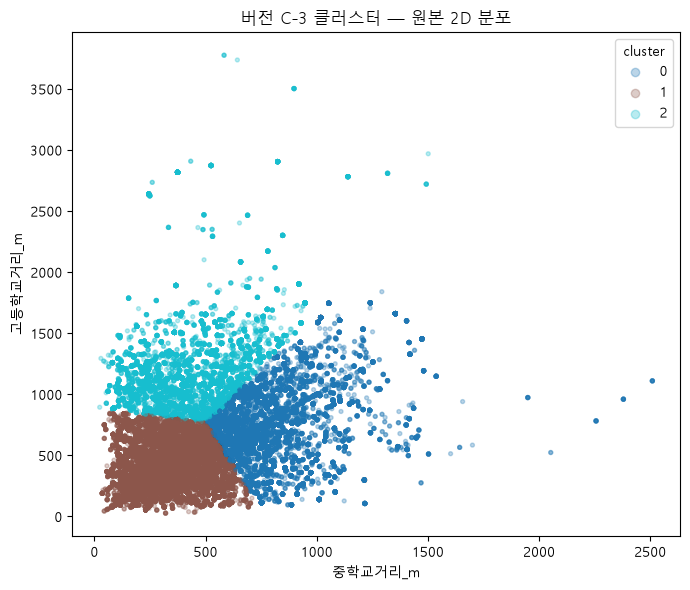

In [ ]:
# 버전 C-3 — 원본 2D 분포 (중학교거리 vs 고등학교거리, 이미 2차원이라 PCA 불필요)
plt.figure(figsize=(7, 6))
scatter = plt.scatter(
    df_cluster_secondary["중학교거리_m"], df_cluster_secondary["고등학교거리_m"],
    c=df_cluster_secondary["cluster"], cmap="tab10", alpha=0.3, s=8,
)
plt.xlabel("중학교거리_m")
plt.ylabel("고등학교거리_m")
plt.title("버전 C-3 클러스터 — 원본 2D 분포")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.tight_layout()
plt.show()


In [ ]:
# 버전 D — PCA 2D 시각화 (log_price·전용면적·log_평당가)
pca_d = PCA(n_components=2, random_state=42)
X_pca_d = pca_d.fit_transform(X_cluster_segment)
print(f"2개 주성분이 설명하는 분산 비율: {pca_d.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_pca_d[:, 0], X_pca_d[:, 1], c=kmeans_d.labels_, cmap="tab10", alpha=0.3, s=8)
plt.xlabel("주성분 1")
plt.ylabel("주성분 2")
plt.title("버전 D 클러스터 — PCA 2D 시각화")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.tight_layout()
plt.show()


2개 주성분이 설명하는 분산 비율: 63.9%


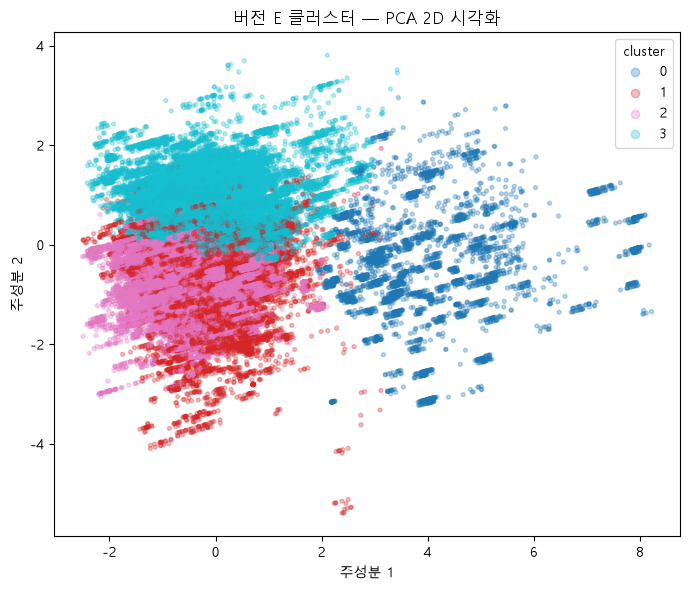

In [ ]:
# 버전 E — PCA 2D 시각화 (log_평당가·연식·역세권거리·초등학교거리)
pca_e = PCA(n_components=2, random_state=42)
X_pca_e = pca_e.fit_transform(X_cluster_value)
print(f"2개 주성분이 설명하는 분산 비율: {pca_e.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_pca_e[:, 0], X_pca_e[:, 1], c=kmeans_e.labels_, cmap="tab10", alpha=0.3, s=8)
plt.xlabel("주성분 1")
plt.ylabel("주성분 2")
plt.title("버전 E 클러스터 — PCA 2D 시각화")
plt.legend(*scatter.legend_elements(), title="cluster")
plt.tight_layout()
plt.show()


## 저장

다음 노트북(회귀·분류)에서 클러스터 정보를 추가 피처로 활용하고 싶을 때 바로 merge할 수 있게, 5개 버전(A~E)의 클러스터 라벨을 모두 저장합니다.

In [ ]:
# cluster_labels = pd.DataFrame({
#     "cluster_region": df_fe["cluster_region"],
#     "cluster_pure": df_fe["cluster_pure"],
#     "cluster_infra": df_fe["cluster_infra"],
#     "cluster_segment": df_fe["cluster_segment"],
#     "cluster_value": df_fe["cluster_value"],
#     "cluster_transit": df_fe["cluster_transit"],
#     "cluster_elem": df_fe["cluster_elem"],
#     "cluster_secondary": df_fe["cluster_secondary"],
#     "cluster_transit_price": df_fe["cluster_transit_price"],
#     "cluster_redevelop": df_fe["cluster_redevelop"],
#     "cluster_dealtype": df_fe["cluster_dealtype"],
# }, index=df_fe.index)

# cluster_labels.to_parquet(PROCESSED_DIR / "cluster_labels.parquet")
# print(f"저장 완료: {PROCESSED_DIR / 'cluster_labels.parquet'}")


## 미해결 / 보류
- **모델(.pkl) 저장 보류** — 회귀와 마찬가지로 지하철역거리·학군 피처 추가 후 재실행 예정
- GMM은 버전 B에만 적용 — C/D/E에도 확장 가능(위 참고 문단)
- DBSCAN 등 밀도 기반 알고리즘은 아직 비교 안 해봄

## 다음 단계
`04_regression.ipynb`에서 `cluster_labels.parquet`를 merge해서 군집 결과를 회귀 피처로 활용할 수 있습니다. `05_classification.ipynb`로도 이어갈 수 있습니다.

## 부록 — k값 재검토

각 버전에서 "실루엣 스코어가 가장 높은 k"를 그대로 쓰지 않고, 해당 버전을 만든 목적에 비춰 다시 검토했다.

| 버전 | 최초 k | 최종 k | 비고 |
|---|---|---|---|
| A (지역포함) | 6 | **10** | 실제 최고점은 k=10(0.209) — 대조군이므로 통계적 최고점 그대로 채택 |
| B (지역제외) | 5 | 5 | 이미 최고점(0.228)과 일치 |
| C (인프라 종합) | 4 | 4 | 최고점은 k=3(0.293)이지만 "역세권형"과 "학군형"이 합쳐져 버려서 이 버전의 목적(교통 vs 학군 구분)이 사라짐 — k=4(0.285)가 최고점과 거의 차이 없이 구분을 유지 |
| C-1 (역세권 단독) | 4 | **6** | k=4(0.653)는 "가까운" 클러스터가 0~793m(평균 430m, 78%)를 통째로 묶어 진짜 초역세권(300m 이내)과 역세권(500~800m)이 구분 안 됨. k=6(0.585)로 올리면 가장 가까운 클러스터가 평균 343m(29~544m)로 좁혀져 "초역세권"이라 부를 만한 실제 근거리 구간이 나옴 |
| C-2 (초등학군) | 4 | 4 | 최고점 k=2(0.595)는 34%/66% 단순 이분할 — k=4가 "초품아" 등 세분 구간(176m~693m)을 보여줘 활용도가 더 높음 |
| C-3 (중고등학군) | 4 | **3** | 최고점 k=3(0.434)이 기존 k=4(0.379)보다 뚜렷이 높고 26%/59%/15%로 균형도 좋아 반영 |
| D (가격·평형 세그먼트) | 4 | **5** | 통계적 최고점은 k=9(0.392)지만 9개는 마케팅 페르소나로 쓰기엔 과함 — k=5(0.382, 최고점과 거의 차이 없음)가 7~29%로 균등하고 해석 가능한 5개 세그먼트를 만들어냄 |
| E (가격대비인프라) | 4 | 4 | 최고점 k=2(0.558)도 C-1과 같은 95%/5% 이상치 분할 — 이상치 제외 시 k=4가 실질 최고점 |

**기준**: 특히 1차원 거리 피처(C-1, C-2, E)에서는 최고 실루엣이 거의 항상 "극단적 이상치 소수 vs 나머지"로 나뉘는데, 통계적으로는 가장 잘 분리되어 보여도 비즈니스적으로는 쓸모가 없다. 이런 경우 이상치 분할을 제외한 범위에서 최고점을 다시 찾거나, 해당 버전이 원래 의도한 해석(계단식 구간, 유형 구분 등)이 유지되는 k를 우선했다.

**추가 교훈 (C-1)**: 근거리에 데이터가 촘촘히 몰려있는 분포에서는 k를 조금 늘려도 분리력이 대부분 "소수 원거리 이상치를 더 잘게 쪼개는 데"만 쓰이고, 정작 필요한 근거리 구간 세분화에는 잘 안 쓰인다. "초역세권" 같은 업계 통념에 맞는 라벨을 붙이려면, 클러스터 평균값이 실제로 그 정의(예: 300m 이내)에 부합하는지 반드시 직접 확인해야 한다 — 실루엣 점수만으로는 이 괴리를 잡아낼 수 없었다.

## 부록 — 버전별 비즈니스 활용 판단

**바로 쓸 수 있는 것**
- **D (5개 소비자 세그먼트)**: 거래금액·평형·평당가가 뚜렷이 갈리는 5개 그룹(저가소형 / 강남권 프리미엄 소형·중형 / 실속형 소형 / 자산가용 대형 / 중산층 중형)이 나옴 — 매물 상세페이지의 "비슷한 예산대" 필터나 영업 세그먼트 태그로 바로 활용 가능.
- **C-1 / C-2 / C-3 (역세권·학군 단독)**: 계단식 구간이 뚜렷해서 "초역세권만 보기", "초품아만 보기" 같은 스크리닝 필터로 즉시 활용 가능. 지역과 무관하게 서울 전역에 통일된 기준을 제공한다는 점이 강점. (C-1은 k=6으로 올린 뒤에야 실제 "초역세권" 수준의 근거리 클러스터가 나왔다는 점 주의)
- **B (신축소형 vs 일반구축)**: 지역을 초월한 매물 유형 발견 — "신축소형 매물 스크리닝/추천" 기능에 바로 연결.

**참고용 / 2차 활용**
- **E (저평가 후보군)**: "평당가는 낮은데 인프라는 좋은" 클러스터가 실제로 존재하는지가 핵심 — `cluster_summary_e`를 평당가·거리 기준으로 정렬해 직접 확인 필요(위 정렬 셀 참고). 존재한다면 05(분류) 노트북의 저평가 스크리닝과 바로 연결되는 가장 스토리가 좋은 발견이 될 수 있음.
- **C (인프라 종합)**: crosstab으로 특정 클러스터가 여러 구에 고르게 퍼져 있는지 확인 필요 — 그래야 "지역과 무관한 인프라 유형"이라는 주장이 성립.

**활용도 낮음 (대조군 역할)**
- **A (지역포함)**: 클러스터가 사실상 구 단위 재현이라 새로운 인사이트는 아님 — "지역이 얼마나 강력한 신호인지" 보여주는 대조군으로만 포트폴리오에 남긴다.
